In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path('/Users/wang/Downloads/AO')
WAVELENGTH_UM = 0.633

assert DATA_DIR.is_dir(), f'Data directory not found: {DATA_DIR}'
print(f'Using data directory: {DATA_DIR}')

Using data directory: /Users/wang/Downloads/AO


In [31]:
def load_grid(filename):
    """Load a tab-separated camera array with decimal commas."""
    rows = []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if fields:
            rows.append([np.nan if x == 'NaN' else float(x.replace(',', '.')) for x in fields])
    return np.asarray(rows, dtype=float)

def load_wfe(filename):
    """Return a dataframe with time, P2V, and RMS from the WFS export."""
    rows = []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if len(fields) >= 4:
            try:
                rows.append([float(fields[0].replace(',', '.')),
                             float(fields[1].replace(',', '.')),
                             float(fields[3].replace(',', '.'))])
            except ValueError:  # skip the header row
                pass
    return pd.DataFrame(rows, columns=['time', 'p2v_um', 'rms_um'])

def fwhm(profile):
    """
    FWHM in pixels from a 1D profile. Background is the median of the
    first and last 10% of pixels; half-height crossings use linear interpolation.
    """
    profile = np.asarray(profile, dtype=float)
    edge = max(5, len(profile) // 10)
    background = np.median(np.r_[profile[:edge], profile[-edge:]])
    peak_index = int(np.nanargmax(profile))
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)

    left_candidates = np.where(profile[:peak_index] < half)[0]
    right_candidates = np.where(profile[peak_index + 1:] < half)[0]
    if len(left_candidates) == 0 or len(right_candidates) == 0:
        raise ValueError('The profile does not cross half maximum on both sides.')

    left_index = left_candidates[-1]
    right_index = peak_index + 1 + right_candidates[0]
    left_crossing = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right_crossing = (right_index - 1
                      + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1]))
    return dict(width_px=right_crossing - left_crossing, left_px=left_crossing,
                right_px=right_crossing, peak_px=peak_index, peak=peak,
                background=background, half=half)

def analyse_state(label, wfe_file, image_file):
    wfe = load_wfe(wfe_file)
    image = load_grid(image_file)
    peak_row, peak_col = np.unravel_index(np.nanargmax(image), image.shape)
    x_profile = image[peak_row, :]
    y_profile = image[:, peak_col]
    rms_mean = wfe['rms_um'].mean()
    return dict(
        label=label, wfe=wfe, image=image, peak_row=peak_row, peak_col=peak_col,
        x_profile=x_profile, y_profile=y_profile, x_fwhm=fwhm(x_profile), y_fwhm=fwhm(y_profile),
        p2v_mean_um=wfe['p2v_um'].mean(), p2v_sd_um=wfe['p2v_um'].std(ddof=1),
        rms_mean_um=rms_mean, rms_sd_um=wfe['rms_um'].std(ddof=1),
        strehl_marechal=np.exp(-(2 * np.pi * rms_mean / WAVELENGTH_UM) ** 2),
    )

In [33]:
task3 = analyse_state('Task 3 - uncorrected',
                      'Task3_stat_wavefront_err.txt',
                      'Task3_FWHM_raw_data.txt')
task4 = analyse_state('Task 4 - corrected',
                      'Task4_stat_wavefront_err_corr_sys.txt',
                      'Task4_FWHM_raw_data_corr_sys.txt')

summary = pd.DataFrame([
    {'State': task3['label'], 'P2V WFE (um)': task3['p2v_mean_um'], 'P2V SD (um)': task3['p2v_sd_um'],
     'RMS WFE (um)': task3['rms_mean_um'], 'RMS SD (um)': task3['rms_sd_um'],
     'Strehl (Marechal)': task3['strehl_marechal'],
     'FWHM x (px)': task3['x_fwhm']['width_px'], 'FWHM y (px)': task3['y_fwhm']['width_px'],
     'Camera array': f"{task3['image'].shape[0]} x {task3['image'].shape[1]}"},
    {'State': task4['label'], 'P2V WFE (um)': task4['p2v_mean_um'], 'P2V SD (um)': task4['p2v_sd_um'],
     'RMS WFE (um)': task4['rms_mean_um'], 'RMS SD (um)': task4['rms_sd_um'],
     'Strehl (Marechal)': task4['strehl_marechal'],
     'FWHM x (px)': task4['x_fwhm']['width_px'], 'FWHM y (px)': task4['y_fwhm']['width_px'],
     'Camera array': f"{task4['image'].shape[0]} x {task4['image'].shape[1]}"},
])

display(summary.style.format({
    'P2V WFE (um)': '{:.4f}', 'P2V SD (um)': '{:.4f}',
    'RMS WFE (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'Strehl (Marechal)': '{:.3g}', 'FWHM x (px)': '{:.1f}', 'FWHM y (px)': '{:.1f}',
}))

print(f"RMS reduction factor: {task3['rms_mean_um'] / task4['rms_mean_um']:.2f}x")
print(f"P2V reduction factor: {task3['p2v_mean_um'] / task4['p2v_mean_um']:.2f}x")

,State,P2V WFE (um),P2V SD (um),RMS WFE (um),RMS SD (um),Strehl (Marechal),FWHM x (px),FWHM y (px),Camera array
0,Task 3 - uncorrected,12.8096,0.0209,3.26941,0.00529,0,25.0,35.0,101 x 101
1,Task 4 - corrected,0.3398,0.0098,0.07597,0.00321,0.566,30.0,34.0,391 x 427


RMS reduction factor: 43.04x
P2V reduction factor: 37.70x


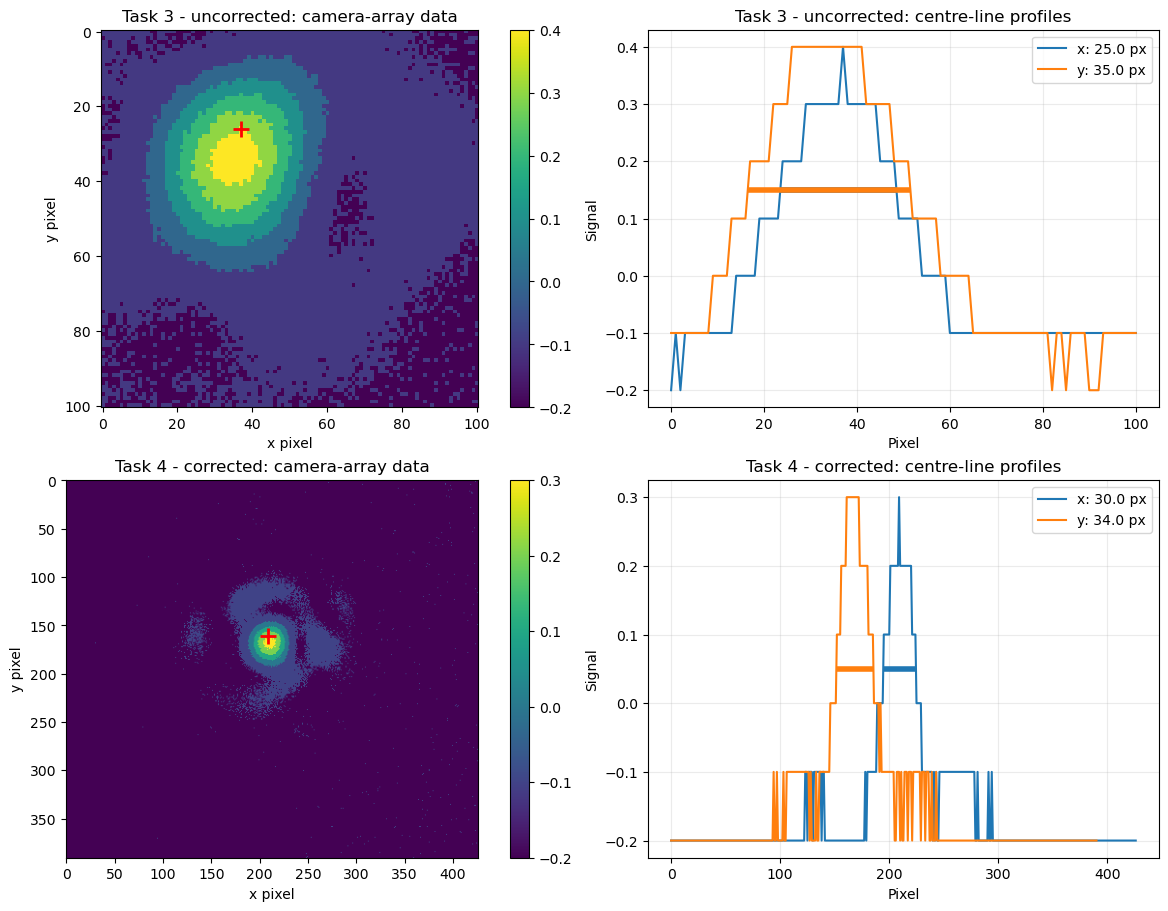

In [35]:
# Camera-array heatmaps and central FWHM profiles
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, state in enumerate([task3, task4]):
    ax = axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f"{state['label']}: camera-array data")
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px")
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
    ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal')
    ax.legend(); ax.grid(alpha=0.25)
plt.show()